PARALLEL CELLULAR ALGORITHM RESULTS
-----------------------------------
Best Solution (x): 1.9994861308153076
Minimum Fitness: 2.640615389764608e-07
Theoretical Minimum: 0 at x = 2


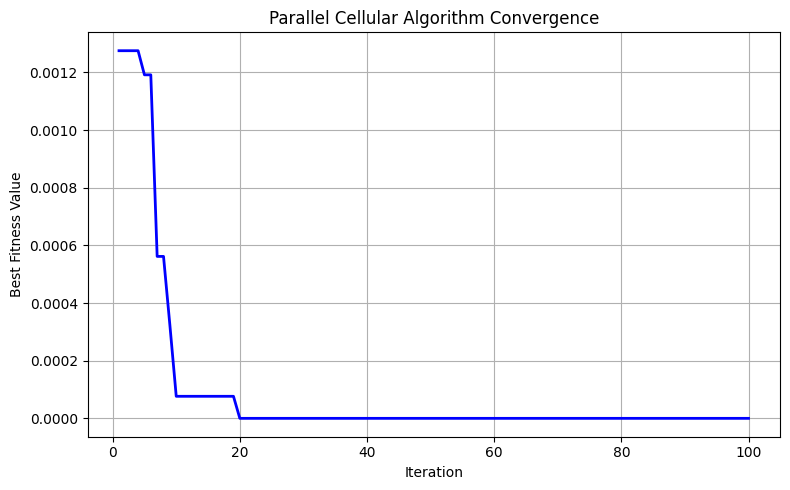

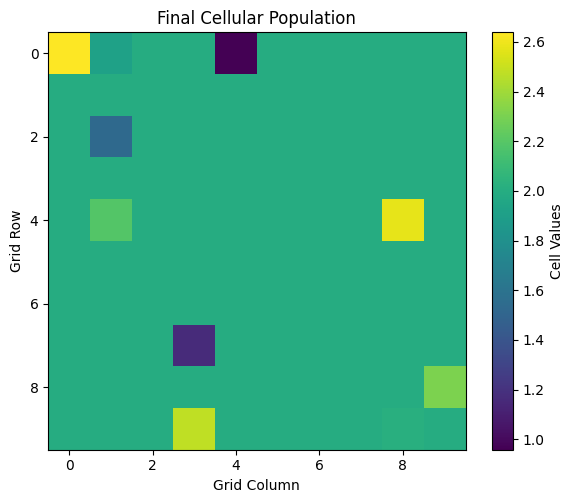

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# PARALLEL CELLULAR ALGORITHM
# Minimize f(x) = (x - 2)^2
# ============================================================

# 1. Parameters
grid_size = 10
iterations = 100
lower_bound = -10
upper_bound = 10
mutation_rate = 0.1
mutation_strength = 0.5

# 2. Fitness Function
def fitness(x):
    return (x - 2) ** 2


# 3. Initialize Population
# 10 x 10 grid = 100 cells
cells = np.random.uniform(
    lower_bound,
    upper_bound,
    (grid_size, grid_size)
)

# Store convergence history
history = []

# 4. Parallel Cellular Algorithm
for iteration in range(iterations):

    # Calculate fitness of all cells
    fitness_values = fitness(cells)

    # Store best fitness
    best_fitness = np.min(fitness_values)
    history.append(best_fitness)

    # Create a new grid
    new_cells = cells.copy()

    # 5. Update each cell using its neighborhood
    for i in range(grid_size):
        for j in range(grid_size):

            # Find neighboring cells (Moore neighborhood)
            neighbors = []

            for di in [-1, 0, 1]:
                for dj in [-1, 0, 1]:

                    if di == 0 and dj == 0:
                        continue

                    ni = (i + di) % grid_size
                    nj = (j + dj) % grid_size

                    neighbors.append(cells[ni, nj])

            # Include the current cell
            neighbors.append(cells[i, j])

            # Find the best neighbor
            neighbors = np.array(neighbors)

            neighbor_fitness = fitness(neighbors)

            best_neighbor = neighbors[
                np.argmin(neighbor_fitness)
            ]

            # 6. Selection
            new_value = best_neighbor

            # 7. Mutation
            if np.random.rand() < mutation_rate:
                new_value += np.random.normal(
                    0, mutation_strength
                )

            # Keep value within bounds
            new_value = np.clip(
                new_value,
                lower_bound,
                upper_bound
            )

            new_cells[i, j] = new_value

    # Update all cells simultaneously
    cells = new_cells


# 8. Find the Best Solution
final_fitness = fitness(cells)

best_index = np.unravel_index(
    np.argmin(final_fitness),
    final_fitness.shape
)

best_solution = cells[best_index]
best_value = fitness(best_solution)


# 9. Display Results
print("PARALLEL CELLULAR ALGORITHM RESULTS")
print("-----------------------------------")
print("Best Solution (x):", best_solution)
print("Minimum Fitness:", best_value)
print("Theoretical Minimum: 0 at x = 2")


# 10. Plot Convergence
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, iterations + 1),
    history,
    color='blue',
    linewidth=2
)

plt.title("Parallel Cellular Algorithm Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness Value")
plt.grid(True)
plt.tight_layout()
plt.show()


# 11. Plot Final Cellular Grid
plt.figure(figsize=(6, 5))

plt.imshow(
    cells,
    cmap='viridis',
    interpolation='nearest'
)

plt.colorbar(label='Cell Values')
plt.title("Final Cellular Population")
plt.xlabel("Grid Column")
plt.ylabel("Grid Row")
plt.tight_layout()
plt.show()
